## Linear Regression 2.2: Predicting goals scored by a team in a FIFA WORLD CUP 2026 match

**Contributing Members:** *Nayandeep Shrestha (s397732)  |   Rajat Shrestha ()*

**Target:** `goals_scored`

**Eight explanatory variables:** team FIFA points, opponent FIFA points, team average goals scored (last 10), opponent average goals conceded (last 10), host nation, knockout stage, rest days, previous WC appearances

| *Part 1* | *Nayandeep Shrestha* | Validation, EDA, multicollinearity, train/test split |

| *Part 2* | *Rajat Shrestha* | OLS model, diagnostics, evaluation, improvement, Poisson Comparison|

## Imports

In [12]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [13]:
# Settings used throughout the notebook
SEED = 42
TARGET = "goals_scored"
NUMERIC_FEATURES = ["team_fifa_points", "opp_fifa_points", "team_gf_L10", "opp_ga_L10", "rest_days", "team_wc_appearances"]
BINARY_FEATURES = ["is_host", "is_knockout"]
FEATURES = NUMERIC_FEATURES[:4] + BINARY_FEATURES + NUMERIC_FEATURES[4:]

LABELS = {
    "team_fifa_points": "Team FIFA Points",
    "opp_fifa_points": "Opponent FIFA Points",
    "team_gf_L10": "Team avg goals scored(Last 10)",
    "opp_ga_L10": "Opponent avg goals conceded(Last 10)",
    "is_host": "Is Host",
    "is_knockout": "Is Knockout Match",
    "rest_days": "Rest Days",
    "team_wc_appearances": "Prev WC Appearances",
    "goals_scored": "Goals Scored",
}

FIG_DIR, TAB_DIR = Path("outputs/figures"), Path("outputs/tables")
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

def section(title):
    """Prints a section title in the output."""
    print(f"\n{'=' * 80}\n{title}\n{'=' * 80}\n")

# PART 1

In [14]:
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(SEED)

def save_fig(name: str) -> None:
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()
    print(f"Figure saved to {FIG_DIR / name}")

### 1. Load and Validate

In [15]:
df= pd.read_csv("wc2026_reg22_dataset.csv")

section("Data Validation")
print(f"Data shape: {df.shape}")
print(f"Data types:\n{df.dtypes.to_string()}")

checks = {
    "208 rows": len(df) == 208,
    "104 unique matches": df["match_id"].nunique() == 104,
    "every match has 2 rows": df["match_id"].value_counts().eq(2).all(),
    "48 unique teams": df["team"].nunique() == 48,
    "exactly 8 explanatory variables": len(FEATURES) == 8,
    "no missing values": df.isna().sum().sum() == 0,
    "no duplicate rows": not df.duplicated(["match_id", "team"]).any(),
    "binary features are 0 or 1": df[BINARY_FEATURES].isin([0, 1]).all().all(),
    "goals scored is non-negative": bool((df[TARGET] >= 0).all() and (df[TARGET] % 1 == 0).all()),
    "rest days is non-negative": bool((df["rest_days"] >= 0).all()),
}

for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")

# each match has two mirrored rows
mirror = df.merge(df[["match_id", "team", TARGET]].rename(columns={"team": "opponent", TARGET: "opp_goals"}),
                  on=["match_id", "opponent"])
print(f" [OK] mirrored opponent rows fould for all rows: {len(mirror) == len(df)}")


Data Validation

Data shape: (208, 13)
Data types:
match_id                object
team                    object
opponent                object
stage                   object
team_fifa_points       float64
opp_fifa_points        float64
team_gf_L10            float64
opp_ga_L10             float64
is_host                  int64
is_knockout              int64
rest_days                int64
team_wc_appearances      int64
goals_scored             int64
[OK] 208 rows
[OK] 104 unique matches
[OK] every match has 2 rows
[OK] 48 unique teams
[OK] exactly 8 explanatory variables
[OK] no missing values
[OK] no duplicate rows
[OK] binary features are 0 or 1
[OK] goals scored is non-negative
[OK] rest days is non-negative
 [OK] mirrored opponent rows fould for all rows: True


### 2. Descriptive Statistics

In [16]:
section("Descriptive Statistics")

desc= df[FEATURES + [TARGET]].describe().T
desc["skewness"] = df[FEATURES + [TARGET]].skew()
desc = desc.round(3)
print(desc.to_string())
desc.to_csv(TAB_DIR / "descriptive_statistics.csv")



Descriptive Statistics

                     count      mean      std      min      25%       50%       75%      max  skewness
team_fifa_points     208.0  1617.207  162.682  1275.58  1505.35  1602.125  1745.072  1877.27    -0.126
opp_fifa_points      208.0  1617.207  162.682  1275.58  1505.35  1602.125  1745.072  1877.27    -0.126
team_gf_L10          208.0     1.959    0.672     0.70     1.30     1.900     2.500     3.70     0.312
opp_ga_L10           208.0     0.865    0.423     0.20     0.50     0.900     1.000     2.00     0.522
is_host              208.0     0.072    0.259     0.00     0.00     0.000     0.000     1.00     3.332
is_knockout          208.0     0.308    0.463     0.00     0.00     0.000     1.000     1.00     0.839
rest_days            208.0     5.221    0.845     3.00     5.00     5.000     6.000     8.00     0.337
team_wc_appearances  208.0     8.149    6.210     0.00     3.00     6.000    14.000    22.00     0.492
goals_scored         208.0     1.481    1.393   

### 3. Target Variable (goals scored by a team in a match)


Mean = 1.481, variance = 1.942, variance/mean = 1.31
(For a Poisson count variable variance ~ mean. A ratio far above 1 means overdispersion.)
Share of rows with 0 goals: 26.4%; max goals: 7

Frequency of goals scored:
 goals_scored
0    55
1    71
2    39
3    25
4    10
5     5
6     2
7     1


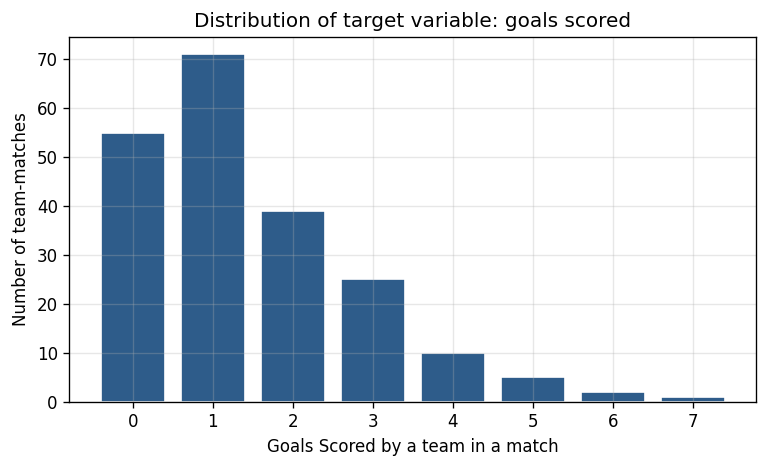

Figure saved to outputs\figures\target_distribution.png
              observed  expected
goals_scored                    
0                   55      47.3
1                   71      70.1
2                   39      51.9
3                   25      25.6
4                   10       9.5
5                    5       2.8
6                    2       0.7
7                    1       0.1


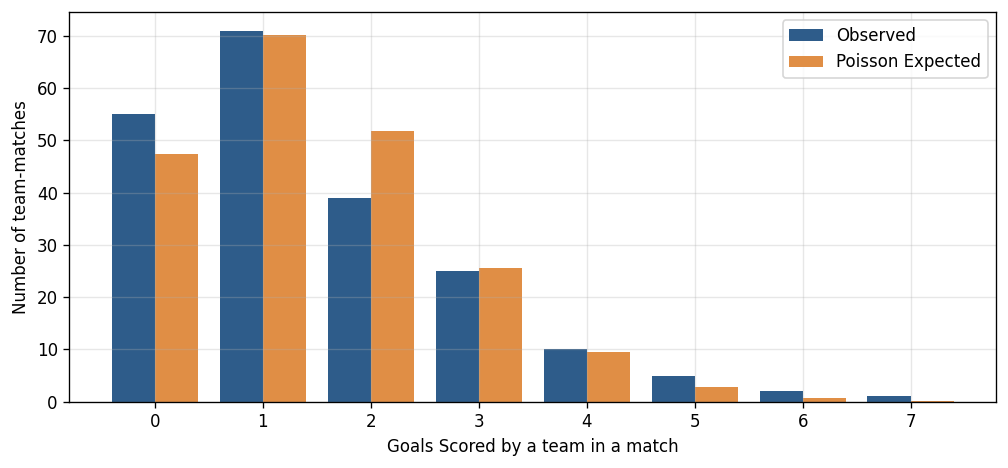

Figure saved to outputs\figures\target_observed_vs_expected.png


In [17]:
y = df[TARGET]
print(f"Mean = {y.mean():.3f}, variance = {y.var():.3f}, variance/mean = {y.var() / y.mean():.2f}")
print("(For a Poisson count variable variance ~ mean. A ratio far above 1 means overdispersion.)")
print(f"Share of rows with 0 goals: {(y == 0).mean():.1%}; max goals: {y.max()}")
counts = y.value_counts().sort_index()
print("\nFrequency of goals scored:\n", counts.to_string())
counts.rename("rows").to_csv(TAB_DIR / "goals_frequency.csv")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(counts.index, counts.values, color="#2e5c8a", edgecolor="white")
ax.set_xlabel("Goals Scored by a team in a match")
ax.set_ylabel("Number of team-matches")
ax.set_title("Distribution of target variable: goals scored")
ax.set_xticks(counts.index)
save_fig("target_distribution.png")

# Observed vs Poisson expected goal counts
k = np.arange(y.max() + 1)
observed = y.value_counts().reindex(k, fill_value=0)
expected = stats.poisson.pmf(k, y.mean()) * len(y)
print(pd.DataFrame({"observed": observed, "expected": expected.round(1)}))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(k - 0.2, observed, 0.4, label="Observed", color="#2e5c8a")
ax.bar(k + 0.2, expected, 0.4, label="Poisson Expected", color="#e08e45")
ax.set_xlabel("Goals Scored by a team in a match")
ax.set_ylabel("Number of team-matches")
ax.set_xticks(k)
ax.legend()
save_fig("target_observed_vs_expected.png")

### 4. Distirbution of Predictors + Outliers

Histograms of the numeric predictors, bar charts of the binary ones, and an IQR-based outlier check

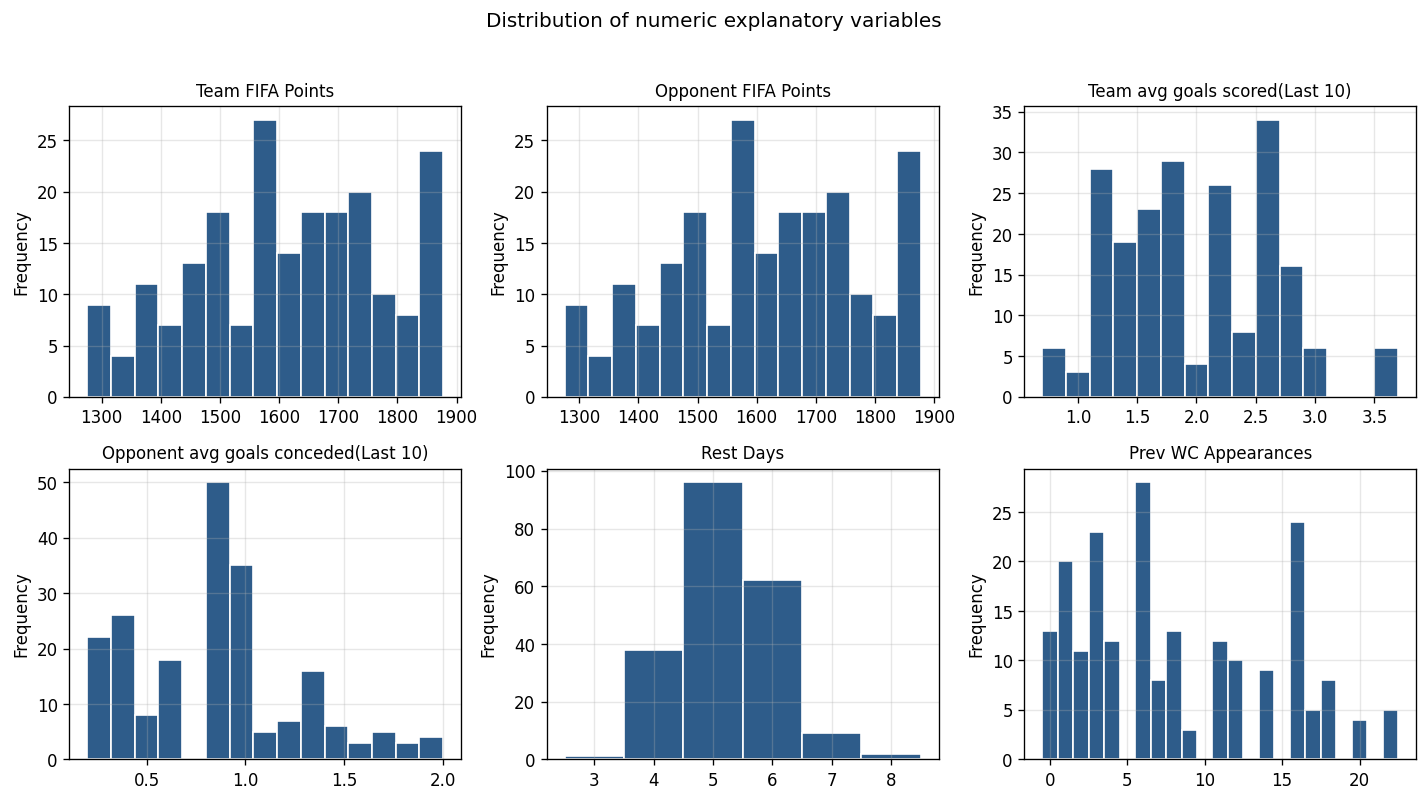

Figure saved to outputs\figures\numeric_features_distribution.png


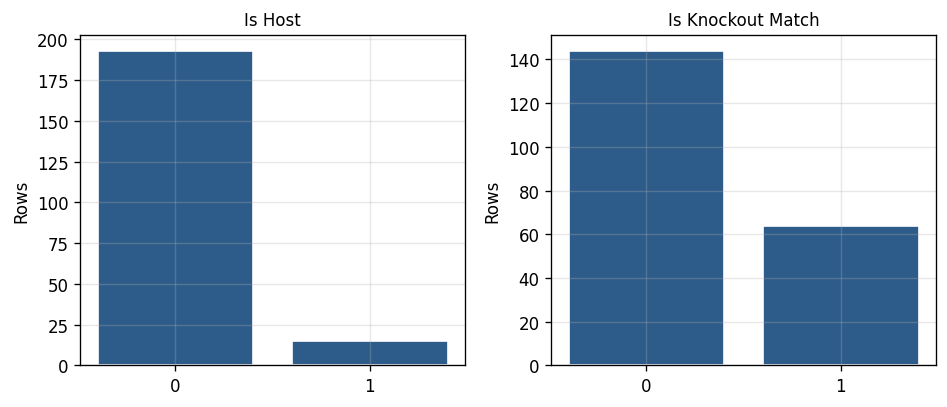

Figure saved to outputs\figures\binary_features_distribution.png
           variable  lower_fence  upper_fence  rows_flagged                                                   flagged_values
   team_fifa_points      1145.77      2104.66             0                                                                 
    opp_fifa_points      1145.77      2104.66             0                                                                 
        team_gf_L10        -0.50         4.30             0                                                                 
         opp_ga_L10        -0.25         1.75             7                      New Zealand: 1.8 (3rows); Sweden: 2 (4rows)
          rest_days         3.50         7.50             3 Australia: 8 (1rows); England: 3 (1rows); Switzerland: 8 (1rows)
team_wc_appearances       -13.50        30.50             0                                                                 


In [18]:
# Histograms of numeric explanatory variables
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    if (df[col] % 1  == 0).all():
        bins = np.arange(df[col].min() - 0.5, df[col].max() + 1.5)
    else:
        bins = 15
    ax.hist(df[col], bins=bins, color="#2e5c8a", edgecolor="white")
    if df[col].nunique() <= 10:
        ax.set_xticks(sorted(df[col].unique()))
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_ylabel("Frequency")
fig.suptitle("Distribution of numeric explanatory variables", y=1.02)
save_fig("numeric_features_distribution.png")

# Bar plots of binary explanatory variables
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, col in zip(axes, BINARY_FEATURES):
    vc = df[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="#2e5c8a", edgecolor="white")
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_ylabel("Rows")
save_fig("binary_features_distribution.png")

# Outlier Check using IQR method
rows = []
for col in NUMERIC_FEATURES:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    owner = "opponent" if col.startswith("opp_") else "team"
    flagged = outliers.groupby(owner)[col].agg(["first", "size"])
    rows.append({
        "variable": col,
        "lower_fence": round(lower, 2),
        "upper_fence": round(upper, 2),
        "rows_flagged": len(outliers),
        "flagged_values": "; ".join(f"{t}: {r['first']:g} ({int(r['size'])}rows)" for t, r in flagged.iterrows())})

outliers = pd.DataFrame(rows)
print(outliers.to_string(index=False))
outliers.to_csv(TAB_DIR / "outlier_check.csv", index=False)

### 5. Relationships

Correlation matrix, correlation of each predictor with goals, scatter plots with trend lines, and goal averages by group.

Correlation of each predictor with the target variable (goals scored):
 team_fifa_points       0.385
opp_fifa_points       -0.339
team_wc_appearances    0.336
team_gf_L10            0.303
opp_ga_L10             0.254
is_host                0.104
rest_days             -0.099
is_knockout           -0.013

Strongest correlation between predictors:
            var_1               var_2   corr
team_fifa_points team_wc_appearances  0.780
team_fifa_points         team_gf_L10  0.631
 opp_fifa_points          opp_ga_L10 -0.554
     team_gf_L10 team_wc_appearances  0.509
team_fifa_points         is_knockout  0.337


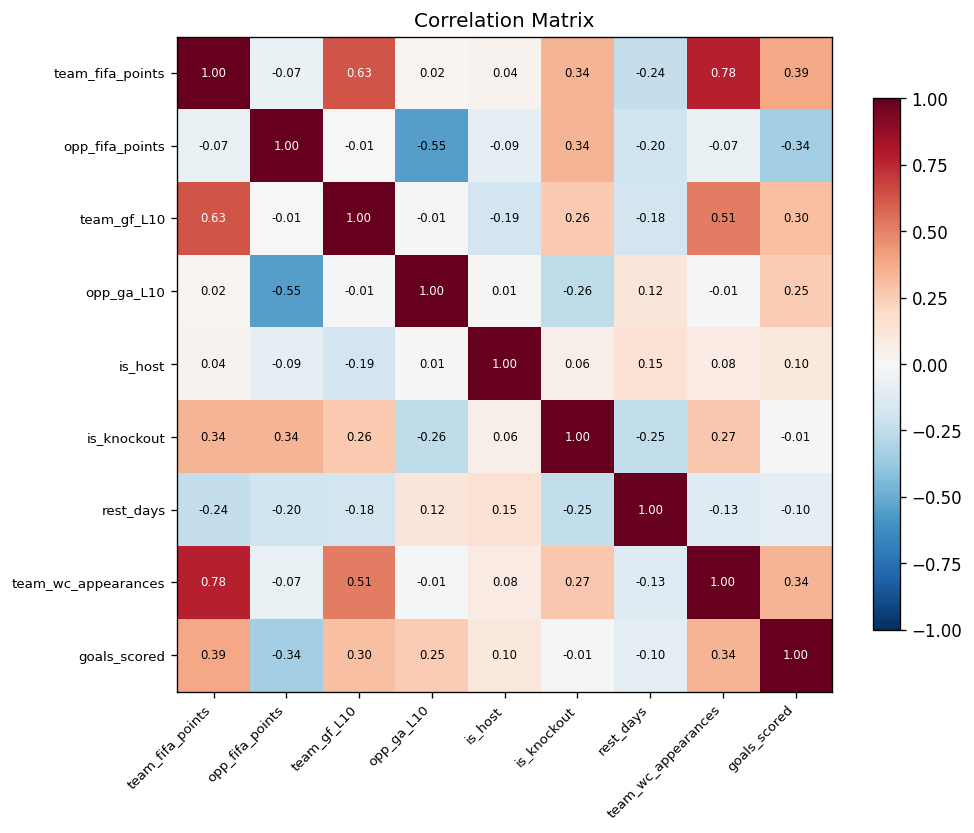

Figure saved to outputs\figures\correlation_heatmap.png


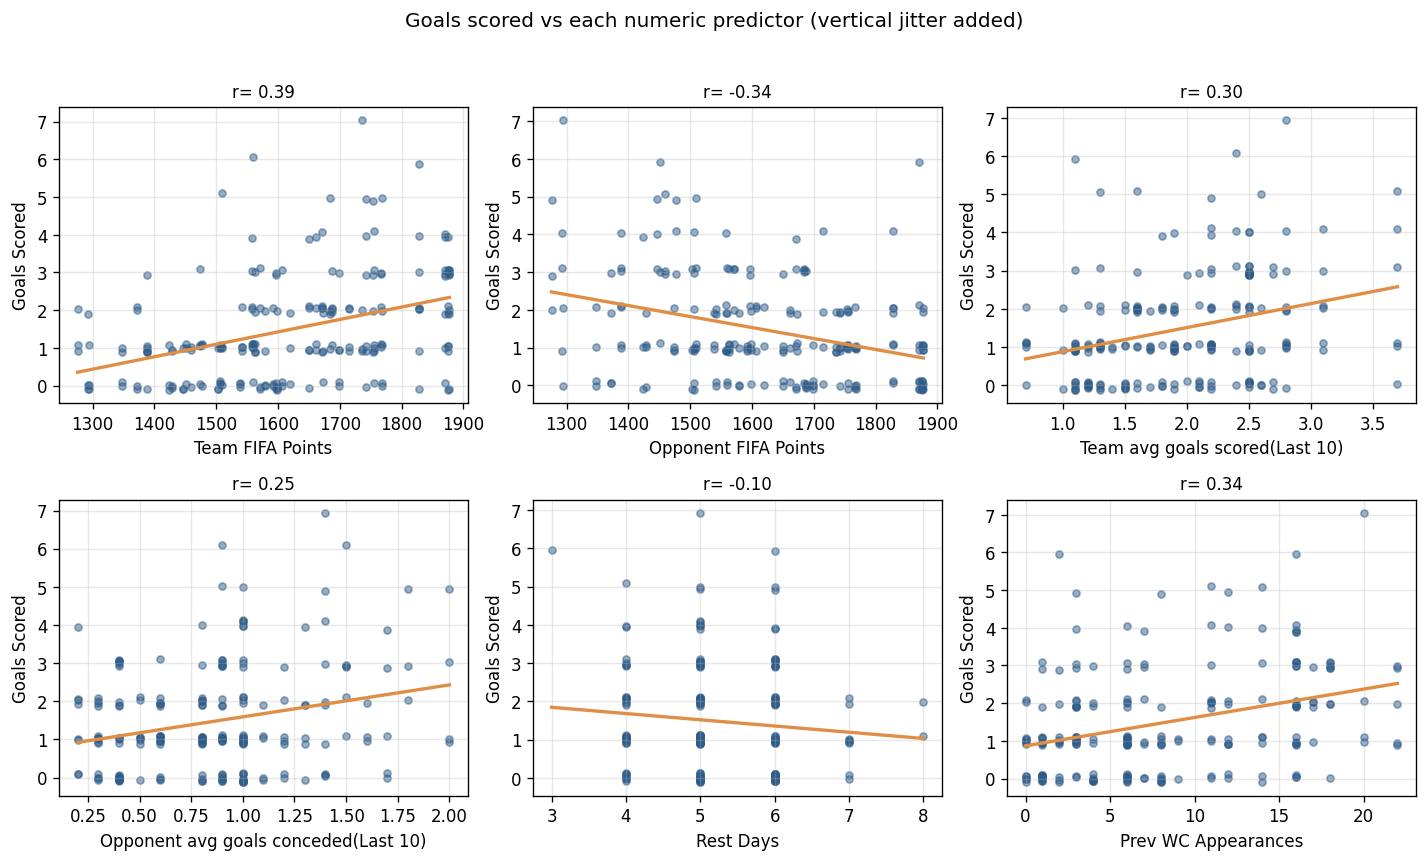

Figure saved to outputs\figures\target_vs_scatter_numeric.png


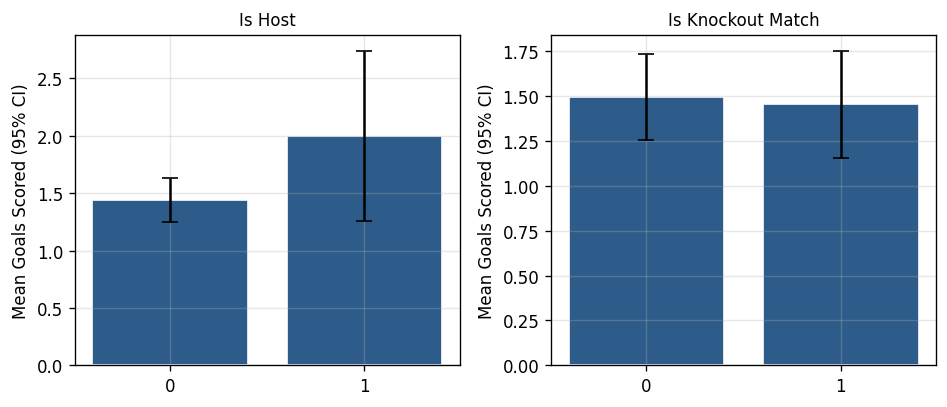

Figure saved to outputs\figures\target_vs_binary.png

Mean goals scored by tournament stage:
                count   mean
stage                      
Bronze final       2  5.000
Final              2  0.500
Group Stage      144  1.493
Quarter-final      8  1.500
Round of 16       16  1.438
Round of 32       32  1.312
Semi-final         4  1.250


In [19]:
cols = FEATURES + [TARGET]
corr = df[cols].corr().round(3)
corr.to_csv(TAB_DIR / "correlation_matrix.csv")

target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Correlation of each predictor with the target variable (goals scored):\n", target_corr.to_string())
target_corr.round(3).rename("corr_with_goals").to_csv(TAB_DIR / "corr_with_target.csv")

pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        pairs.append((a, b, corr.at[a, b]))
pairs = pd.DataFrame(pairs, columns = ["var_1", "var_2", "corr"]).sort_values("corr", key=np.abs, ascending=False)
print("\nStrongest correlation between predictors:\n", pairs.head(5).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.values[i, j]) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation Matrix")
save_fig("correlation_heatmap.png")

# predictor vs target scatter plots
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    jitter = rng.uniform(-0.12, 0.12, len(df))
    ax.scatter(df[col], df[TARGET] + jitter, alpha=0.5, s=18, color="#2e5c8a")
    slope, intercept = np.polyfit(df[col], df[TARGET], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="#e08e45", lw=2)
    ax.set_xlabel(LABELS[col], fontsize=10)
    ax.set_ylabel(LABELS[TARGET])
    ax.set_title(f"r= {corr.loc[col, TARGET]:.2f}", fontsize=10)
fig.suptitle("Goals scored vs each numeric predictor (vertical jitter added)", y = 1.02)
save_fig("target_vs_scatter_numeric.png")

# binary predictors : mean goals per group
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
group_rows = []
for ax, col in zip(axes, BINARY_FEATURES):
    g = df.groupby(col)[TARGET].agg(["mean", "std", "count"])
    g["sem"] = g["std"] / np.sqrt(g["count"])
    ax.bar(g.index.astype(str), g["mean"], yerr=1.96 * g["sem"], capsize=5, color="#2e5c8a", edgecolor="white")
    ax.set_title(LABELS[col], fontsize=10)
    ax.set_ylabel("Mean Goals Scored (95% CI)")
    for level, r in g.iterrows():
        group_rows.append({"variable": col,
                            "level": level,
                            "mean_goals": round(r["mean"], 3), 
                            "sd": round(r["std"], 3),
                            "n": int(r["count"])
                })
save_fig("target_vs_binary.png")
group_table = pd.DataFrame(group_rows)
group_table.to_csv(TAB_DIR / "binary_group_means.csv", index=False)

stage_table = df.groupby("stage")[TARGET].agg(["count", "mean"]).round(3)
print("\nMean goals scored by tournament stage:\n", stage_table.to_string())
stage_table.to_csv(TAB_DIR / "goals_by_stage.csv")

### 6. Multicollinearity (Vif)

Variance inflation factors (Vif) show whether predictors overlap too much.
Rule of thumb: VIF > 5 moderate, >10 serious.

In [20]:
X = sm.add_constant(df[FEATURES])
vif = pd.DataFrame({
    "variable": FEATURES,
    "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(FEATURES))],
}).round(3)
vif["verdict"] = np.where(vif["VIF"] > 10, "serious (>10)", np.where(vif["VIF"] > 5, "moderate (5-10)", "Fine (<5)"))
print(vif.to_string(index=False))
print(f"Condition number of the design matrix: {np.linalg.cond(X.values):.1f}")
print("(This is large mainly because the variables are on very different scales," \
" e.g. FIFA points ~1500 vs binary 0/1. VIF is the more informative check here.)")
vif.to_csv(TAB_DIR / "vif.csv", index=False)

           variable   VIF   verdict
   team_fifa_points 3.411 Fine (<5)
    opp_fifa_points 1.631 Fine (<5)
        team_gf_L10 1.820 Fine (<5)
         opp_ga_L10 1.465 Fine (<5)
            is_host 1.141 Fine (<5)
        is_knockout 1.371 Fine (<5)
          rest_days 1.164 Fine (<5)
team_wc_appearances 2.614 Fine (<5)
Condition number of the design matrix: 55089.3
(This is large mainly because the variables are on very different scales, e.g. FIFA points ~1500 vs binary 0/1. VIF is the more informative check here.)


### 7. Train / Test Split (by match)

Splitting the data 80/20 by match so both rows of a match stay on the same side.

In [22]:
splitter = GroupShuffleSplit(n_splits=1, test_size= 0.20, random_state = SEED)
train_idx, text_idx = next(splitter.split(df, groups=df["match_id"]))
train, test = df.iloc[train_idx].copy(), df.iloc[text_idx].copy()
print(f"Train: {len(train)} rows / {train['match_id'].nunique()} matches")
print(f"Test: {len(test)} rows / {test['match_id'].nunique()} matches")
print(f"Overlap of matches between train and test: {len(set(train['match_id']) & set(test['match_id']))} (must be 0)")
print(f"Mean goals - train: {train[TARGET].mean():.3f}, test: {test[TARGET].mean():.3f}")
print(f"Knockout share - train: {train['is_knockout'].mean():.1%}, test: {test['is_knockout'].mean():.1%}")


Train: 166 rows / 83 matches
Test: 42 rows / 21 matches
Overlap of matches between train and test: 0 (must be 0)
Mean goals - train: 1.590, test: 1.048
Knockout share - train: 30.1%, test: 33.3%
